In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score, silhouette_samples
from sklearn.decomposition import PCA


import umap
import os
import pickle

# Optimal Preprocessing for GMM

In [2]:
df_pre_PCA = pd.read_csv('../PART1/ddos_dataset_pre_PCA.csv', index_col=0)
df_pd = df_pre_PCA.copy()

In [3]:
label_counts = df_pd['label'].value_counts()
df_labels = df_pd['label'].values

In [4]:
# Dropping categorical or useless features
columnsToDrop = ["Flow ID","Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp","label"]
df_pd = df_pd.drop(columns=columnsToDrop)

In [5]:
df_np = df_pd.to_numpy()

df_s_np = StandardScaler().fit_transform(df_np)
df_s_pd = pd.DataFrame(df_s_np, columns=df_pd.columns)

In [6]:
# needed to plot graphs
pca = PCA(n_components=3)
df_pca = pca.fit_transform(df_s_np)

In [7]:
# create this folder to save already computed results
if not os.path.exists("./saved_results"):
    os.makedirs("./saved_results")

### Performing GMM clustering with **12** clusters, corresponding to the number of labels we have, and then computing the relevant metrics.

In [14]:
def gmm_with_info(df, df_labels, k, cv_type, n_samples=None, print_info=True):
    gmm = GaussianMixture(n_components=k, covariance_type=cv_type,n_init=50, max_iter=500, init_params="k-means++", random_state=42)
    cluster_labels = gmm.fit_predict(df)

    log_likelihood=gmm.score(df)
    silhouette_val = silhouette_score(df, cluster_labels, sample_size = n_samples, random_state=42)
    rand_score_val = rand_score(df_labels, cluster_labels)
    adj_rand_score_val = adjusted_rand_score(df_labels, cluster_labels)
    cluster_sizes = gmm.weights_

    results = {
        'k': k,
        'cv_type': cv_type,
        'log_likelihood': round(log_likelihood, 2),
        'silhouette': round(silhouette_val, 2),
        'RI': round(rand_score_val, 2),
        'ARI': round(adj_rand_score_val, 2),
        'cluster_labels': cluster_labels,
        'cluster_sizes': cluster_sizes,
        'centroids' : gmm.means_,
        'n_iter': gmm.n_iter_
    }

    if print_info:
        print(f'## GMM results (k={k}, - Covariance type: {cv_type})')
        print("---")
        print(f"GMM total log-likelihood score:, {results['log_likelihood']}")
        print(f"Silhouette Score : {results['silhouette']}")
        print(f"Rand Index (RI): {results['RI']}")
        print(f"Adjusted Rand Index (ARI): {results['ARI']}")
        print(f"Effetive size of each cluster: {results['cluster_sizes']}")
        print(f"Number of iterations: {results['n_iter']}\n")

    return results

In [24]:
spherical_results_12 = gmm_with_info(df=df_s_np, df_labels=df_labels, k=12, cv_type='spherical',n_samples=None,  print_info=True)
diag_results_12 = gmm_with_info(df=df_s_np, df_labels=df_labels, k=12, cv_type='diag', n_samples=None, print_info=True)
tied_results_12 = gmm_with_info(df=df_s_np, df_labels=df_labels, k=12, cv_type='tied', n_samples=None, print_info=True)
full_results_12 = gmm_with_info(df=df_s_np, df_labels=df_labels, k=12, cv_type='full', n_samples=None, print_info=True)

## GMM results (k=12, - Covariance type: spherical)
---
GMM total log-likelihood score:, -5.69
Silhouette Score : 0.43
Rand Index (RI): 0.85
Adjusted Rand Index (ARI): 0.33
Effetive size of each cluster: [0.08343067 0.04301166 0.04143324 0.22730997 0.10816476 0.0116781
 0.00454096 0.27226393 0.03223582 0.00568191 0.04792079 0.1223282 ]
Number of iterations: 17

## GMM results (k=12, - Covariance type: diag)
---
GMM total log-likelihood score:, 311.38
Silhouette Score : 0.4
Rand Index (RI): 0.85
Adjusted Rand Index (ARI): 0.38
Effetive size of each cluster: [0.11460328 0.06326375 0.03223898 0.28722667 0.0483549  0.00555737
 0.02356824 0.28017008 0.02559193 0.00786127 0.0185515  0.09301203]
Number of iterations: 16

## GMM results (k=12, - Covariance type: tied)
---
GMM total log-likelihood score:, 41.09
Silhouette Score : 0.17
Rand Index (RI): 0.7
Adjusted Rand Index (ARI): 0.17
Effetive size of each cluster: [0.10060579 0.10003832 0.09945755 0.10055086 0.10034288 0.09975017
 0.10041655

# K tuning

In [9]:
def k_tuning(checkpoint_file, start_k, end_k, df, df_labels, cv_type, n_samples=None):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            k_results = pickle.load(f)
        start_k = max(k_results["k"]) + 1
    else:
        k_results = {"k" : [],"cv_type" : [],"log_likelihood" : [],"silhouette" : [],"RI" : [],"ARI" : [],"cluster_labels": [],"cluster_sizes": []}
    if start_k < end_k+1:
        print(f"Resume from k = {start_k}")
        for n_cl in range(start_k, end_k+1):
            results = gmm_with_info(df,df_labels,n_cl,cv_type,n_samples, False)
            k_results["k"].append(results["k"])
            k_results["cv_type"].append(results["cv_type"])
            k_results["log_likelihood"].append(results["log_likelihood"])
            k_results["silhouette"].append(results["silhouette"])
            k_results["RI"].append(results["RI"])
            k_results["ARI"].append(results["ARI"])
            k_results["cluster_labels"].append(results["cluster_labels"])
            k_results["cluster_sizes"].append(results["cluster_sizes"])

            with open(checkpoint_file, "wb") as f:
                pickle.dump(k_results, f)
            print(f"Checkpoint saved for k = {n_cl}")

        print("Loop terminated.")
    else:
        print("Already terminated.")
    return k_results

Calculating GMM results for k between 2 and 40 (covariance type : "spherical")

In [15]:
results_spherical = k_tuning("./saved_results/gmm_spherical_results_2_40.pkl", 2, 40, df_s_np, df_labels, "spherical", None)

Already terminated.


Calculating GMM results for k between 2 and 40 (covariance type : "diag")

In [16]:
results_diag = k_tuning("./saved_results/gmm_diag_results_2_40.pkl", 2, 40, df_s_np, df_labels, "diag", None)

Already terminated.


Calculating GMM results for k between 2 and 40 (covariance type : "tied")

In [17]:
results_tied = k_tuning("./saved_results/gmm_tied_results_2_40.pkl", 2, 40, df_s_np, df_labels, "tied", None)

Already terminated.


Calculating GMM results for k between 2 and 40 (covariance type : "full")

In [18]:
results_full = k_tuning("./saved_results/gmm_full_results_2_40.pkl", 2, 40, df_s_np, df_labels, "full", None)

Already terminated.


## Plot metrics

In [19]:
def plot_metrics(silhouette_list, k_list, log_likelihood_list, ri_list, ari_list, cv_type):
    fig, axs = plt.subplots(2, 2, figsize=(14, 7))

    fig.suptitle(f"Clustering Performance Analysis - Covariance Type: {cv_type}")

    # Silhouette score
    best_silhouette_idx = np.argmax(silhouette_list)
    best_silhouette = silhouette_list[best_silhouette_idx]
    best_silhouette_k = k_list[best_silhouette_idx]
    axs[0, 0].set_title(f'Silhouette score (best k={best_silhouette_k}, silhouette={best_silhouette:.2f})')
    axs[0, 0].plot(k_list, silhouette_list, marker='o', markersize=5)
    axs[0, 0].scatter(best_silhouette_k, best_silhouette, color='r', marker='x', s=90)
    axs[0, 0].set_xlabel('Number of clusters')
    axs[0, 0].set_ylabel('Silhouette score')
    axs[0, 0].grid(alpha=0.5)

    # GMM Log-likelihood'
    best_log_likelihood_idx = np.argmax(log_likelihood_list)
    best_log_likelihood = log_likelihood_list[best_log_likelihood_idx]
    best_log_likelihood_k = k_list[best_log_likelihood_idx]
    axs[0, 1].plot(k_list, log_likelihood_list, marker='o', markersize=5)
    axs[0, 1].scatter(best_log_likelihood_k, best_log_likelihood, color='r', marker='x', s=90)
    axs[0, 1].set_title(f'GMM log-likelihood (best k={best_log_likelihood_k}, log-l.={best_log_likelihood:.2e})')
    axs[0, 1].set_xlabel('Number of clusters')
    axs[0, 1].set_ylabel('GMM log-likelihood')
    axs[0, 1].grid(alpha=0.5)

    # Rand Index (RI)
    best_ri_idx = np.argmax(ri_list)
    best_ri = ri_list[best_ri_idx]
    best_ri_k = k_list[best_ri_idx]
    axs[1, 0].plot(k_list, ri_list, marker='o', markersize=5)
    axs[1, 0].scatter(best_ri_k, best_ri, color='r', marker='x', s=90)
    axs[1, 0].set_title(f'Rand Index (RI) (best k={best_ri_k}, c.e.={best_ri:.2f})')
    axs[1, 0].set_xlabel('Number of clusters')
    axs[1, 0].set_ylabel('RI')
    axs[1, 0].grid(alpha=0.5)

    # Adjusted Rand Index (ARI)
    best_ari_idx = np.argmax(ari_list)
    best_ari = ari_list[best_ari_idx]
    best_ari_k = k_list[best_ari_idx]
    axs[1, 1].plot(k_list, ari_list, marker='o', markersize=5)
    axs[1, 1].scatter(best_ari_k, best_ari, color='r', marker='x', s=90)
    axs[1, 1].set_title(f'Adjusted Rand Index (ARI) (best k={best_ari_k}, c.e.={best_ari:.2f})')
    axs[1, 1].set_xlabel('Number of clusters')
    axs[1, 1].set_ylabel('ARI')
    axs[1, 1].grid(alpha=0.5)


    plt.tight_layout()
    plt.show()

### Plot spherical metrics (for k between 2 and 40)

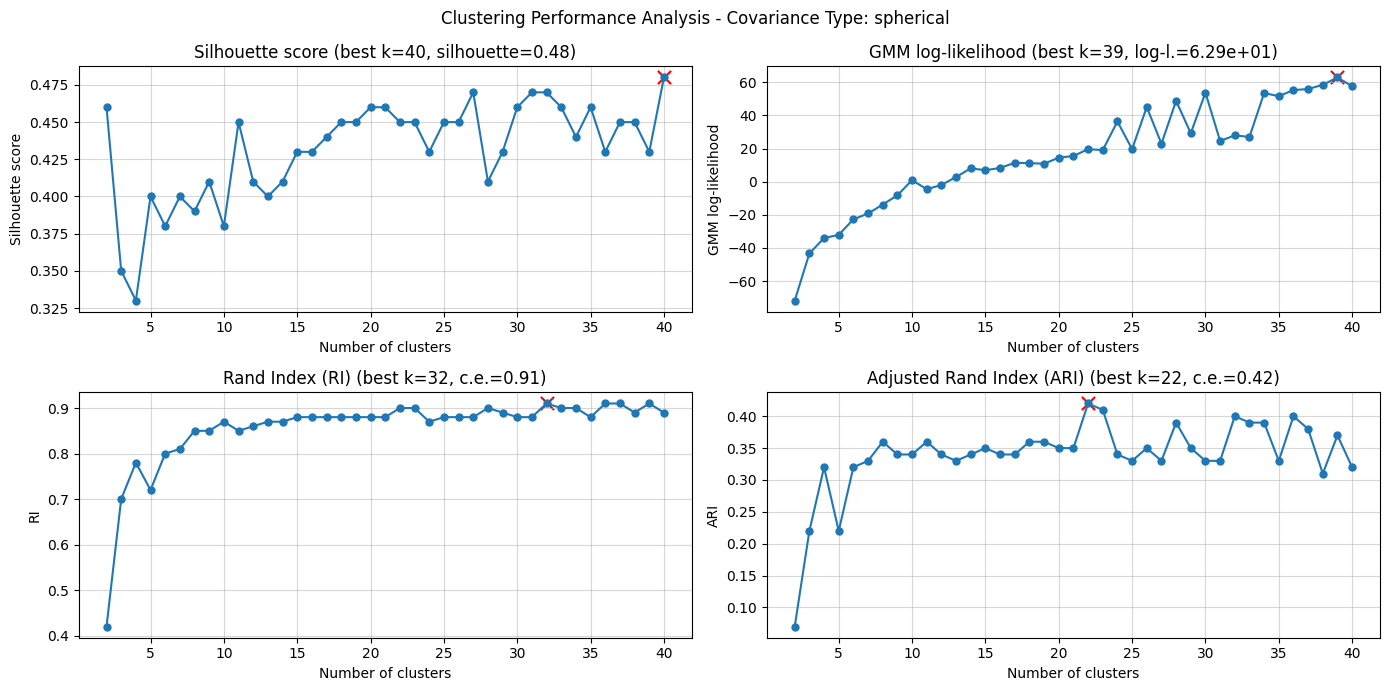

In [20]:
plot_metrics(results_spherical["silhouette"], results_spherical["k"], results_spherical["log_likelihood"], results_spherical["RI"],results_spherical["ARI"], "spherical")

### Plot diag metrics (for k between 2 and 40)

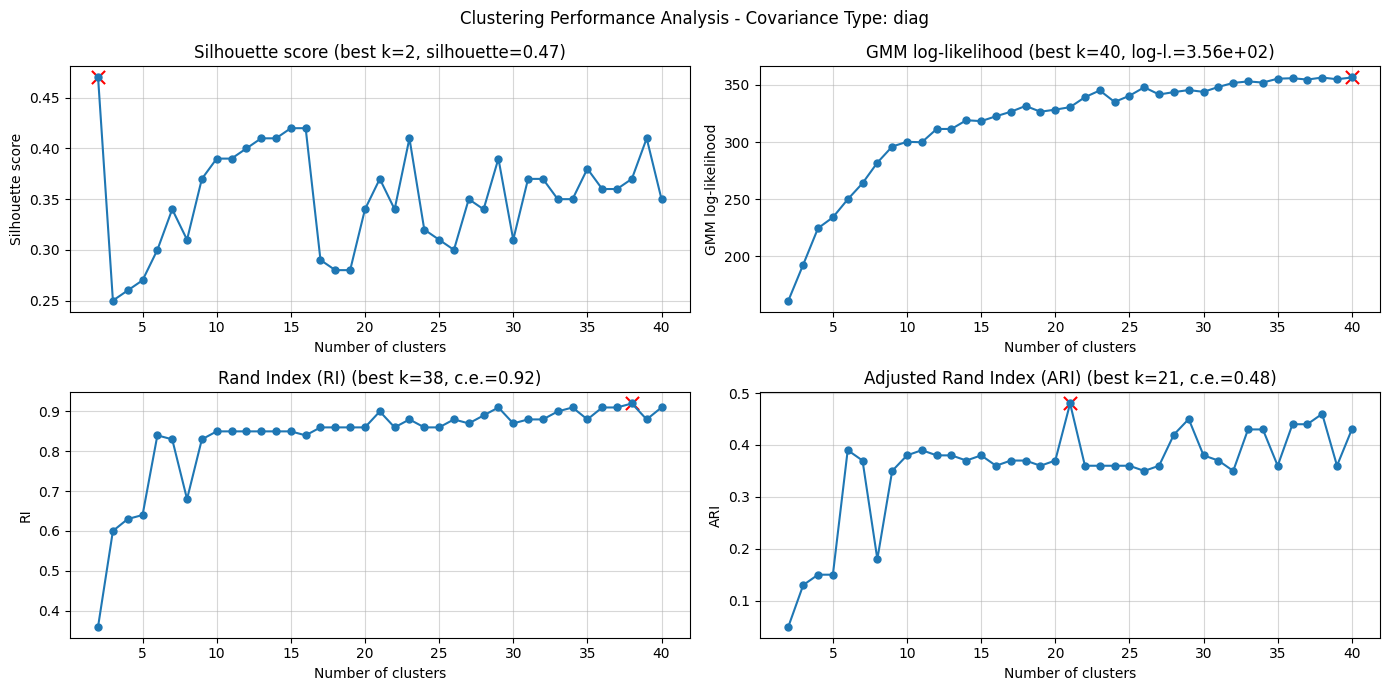

In [21]:
plot_metrics(results_diag["silhouette"], results_diag["k"], results_diag["log_likelihood"], results_diag["RI"],results_diag["ARI"], "diag")

### Plot tied metrics (for k between 2 and 40)

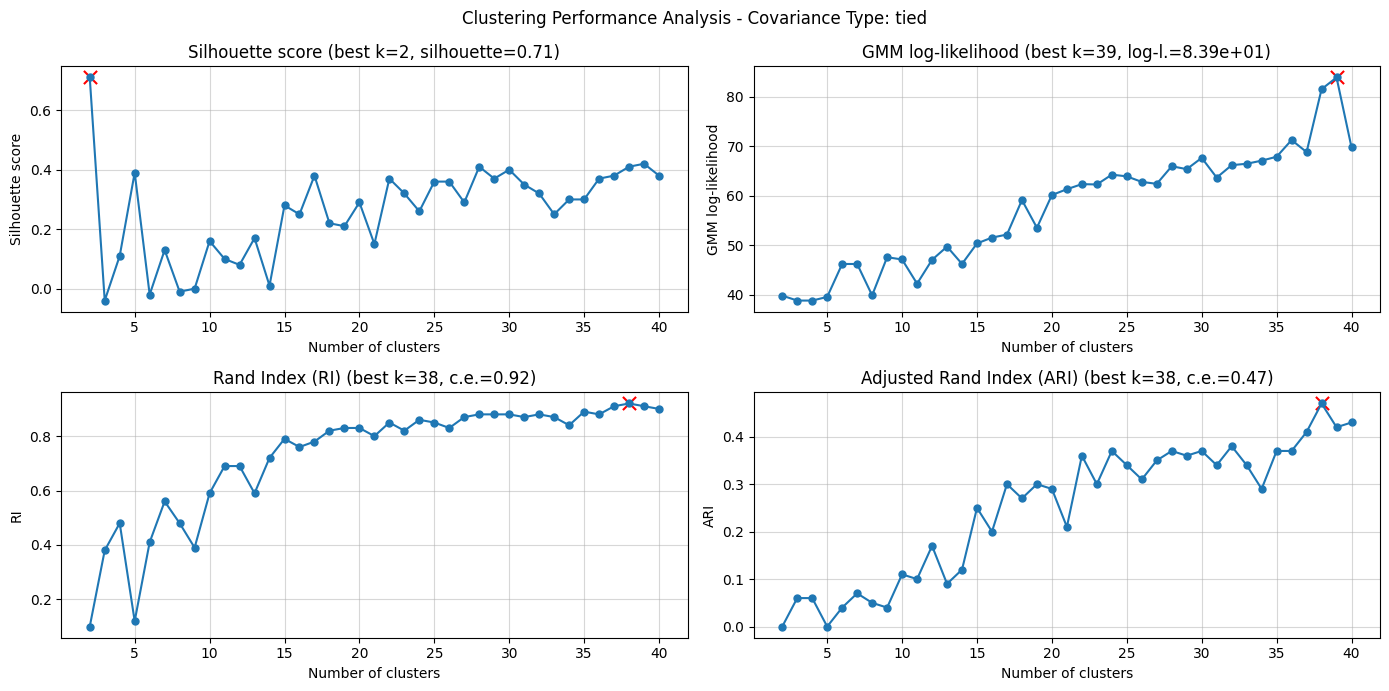

In [22]:
plot_metrics(results_tied["silhouette"], results_tied["k"], results_tied["log_likelihood"], results_tied["RI"],results_tied["ARI"], "tied")

### Plot full metrics (for k between 2 and 40)

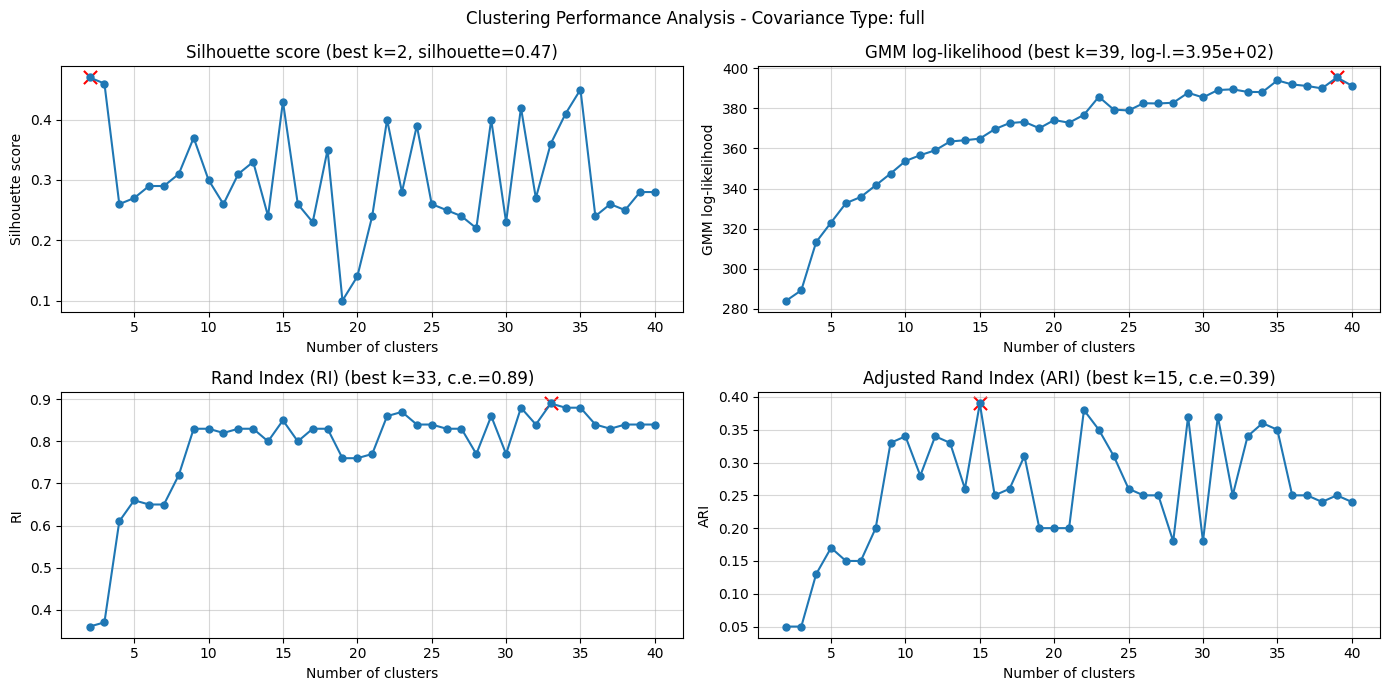

In [23]:
plot_metrics(results_full["silhouette"], results_full["k"], results_full["log_likelihood"], results_full["RI"],results_full["ARI"], "full")

#### Analysis:

1. **Best Covariance Type**: **diag**
    - **Metric Comparison**: The diag configuration provides a superior balance between model fit and clarity. It reaches a significantly higher log-likelihood ($\approx 3.56e+02$) compared to the spherical and tied models. Moreover silhouette and ari show better trends than full and tied.
    - **Optimal Scores**: While the Silhouette score peaks at $k=2$, the diag model shows a strong recovery and stabilization in the $k=8$ to $k=15$ range. At $k=10$, it maintains a solid Silhouette score ($\approx 0.39$) and a high Rand Index, suggesting stable and well-separated clusters.
    - **Model Complexity**:  Network traffic features often have different scales but are not always perfectly correlated. The diag model is more robust than full (which may overfit the noise in high-dimensional traffic data) and more flexible than spherical, making it the most reliable choice for identifying behavioral patterns.
2. **Optimal Cluster Range**: Although $k=2$ is mathematically favored by Silhouette, it is too reductive for a dataset with 12 ground-truth labels. At $k=10$, the log-likelihood begins to show a "diminishing returns" elbow, and the ARI remains competitive. Choosing $k=10$ allows for the emergence of "families" where similar DDoS types (e.g., different volumetric attacks) naturally merge into shared clusters while remaining distinct from benign traffic.

## Plot cluster - label heatmap

In [24]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(22,7))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    if normalize:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (in %)")
    else:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (num of samples)")

    plt.tight_layout()
    plt.show()

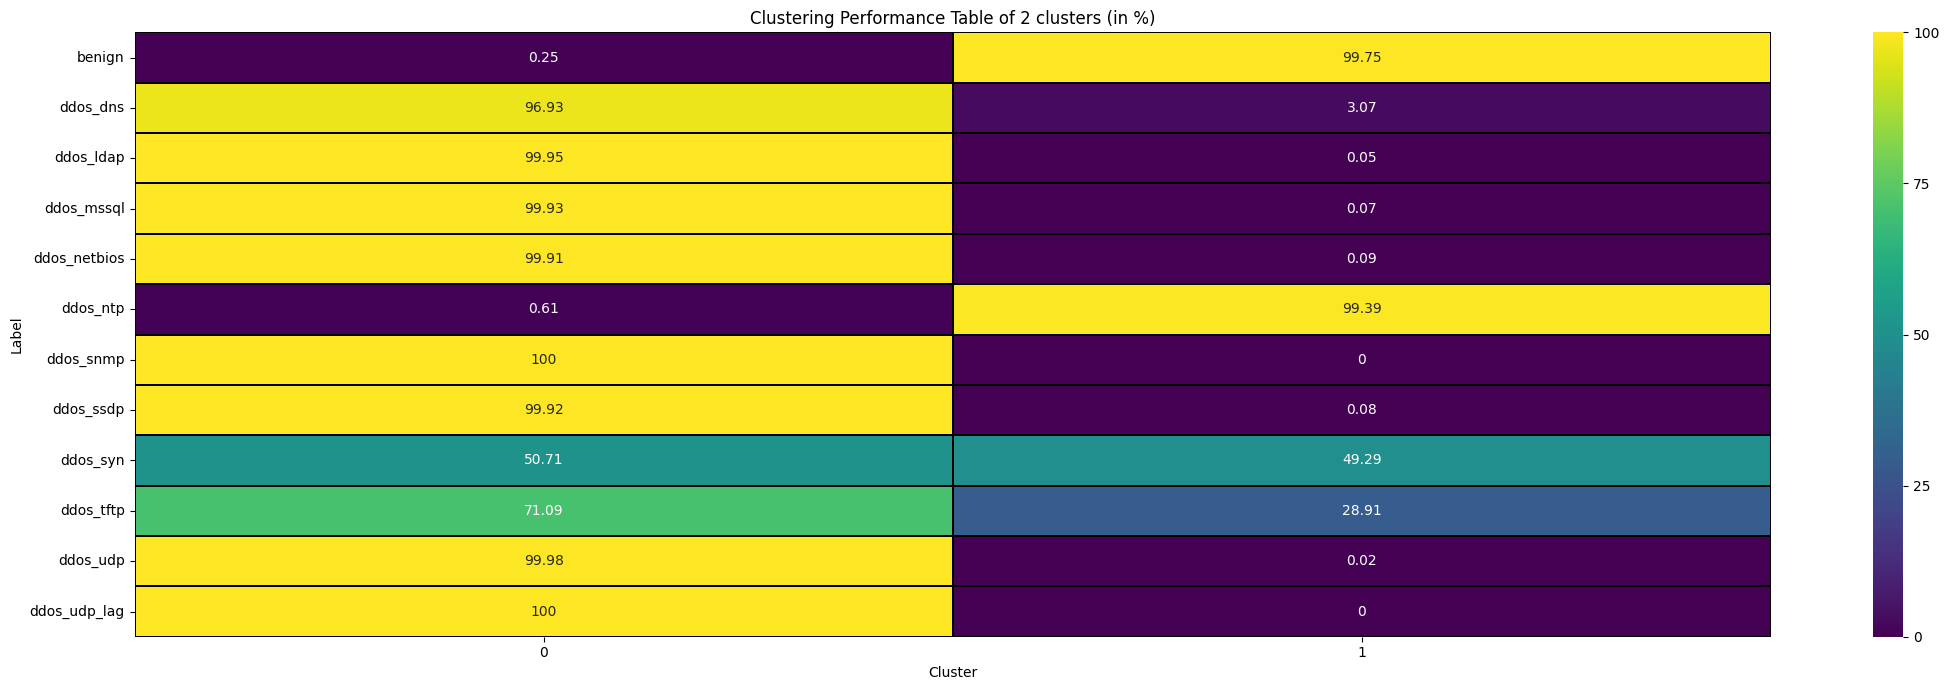

In [25]:
plot_label_cluster_heatmap(results_diag["cluster_labels"][2-2], df_labels, True)

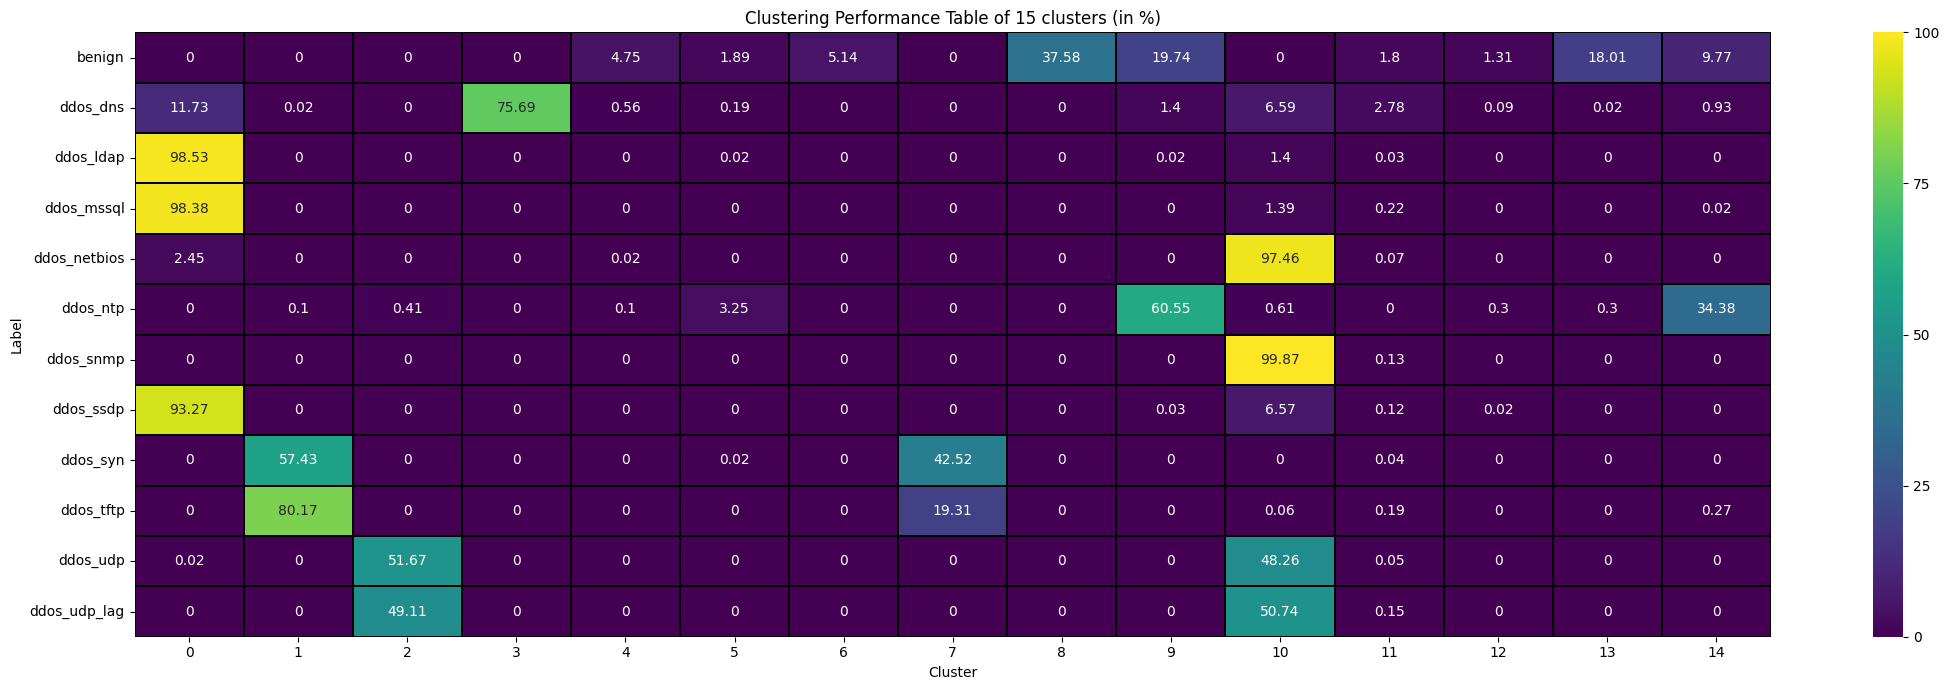

In [26]:
plot_label_cluster_heatmap(results_diag["cluster_labels"][15-2], df_labels, True)

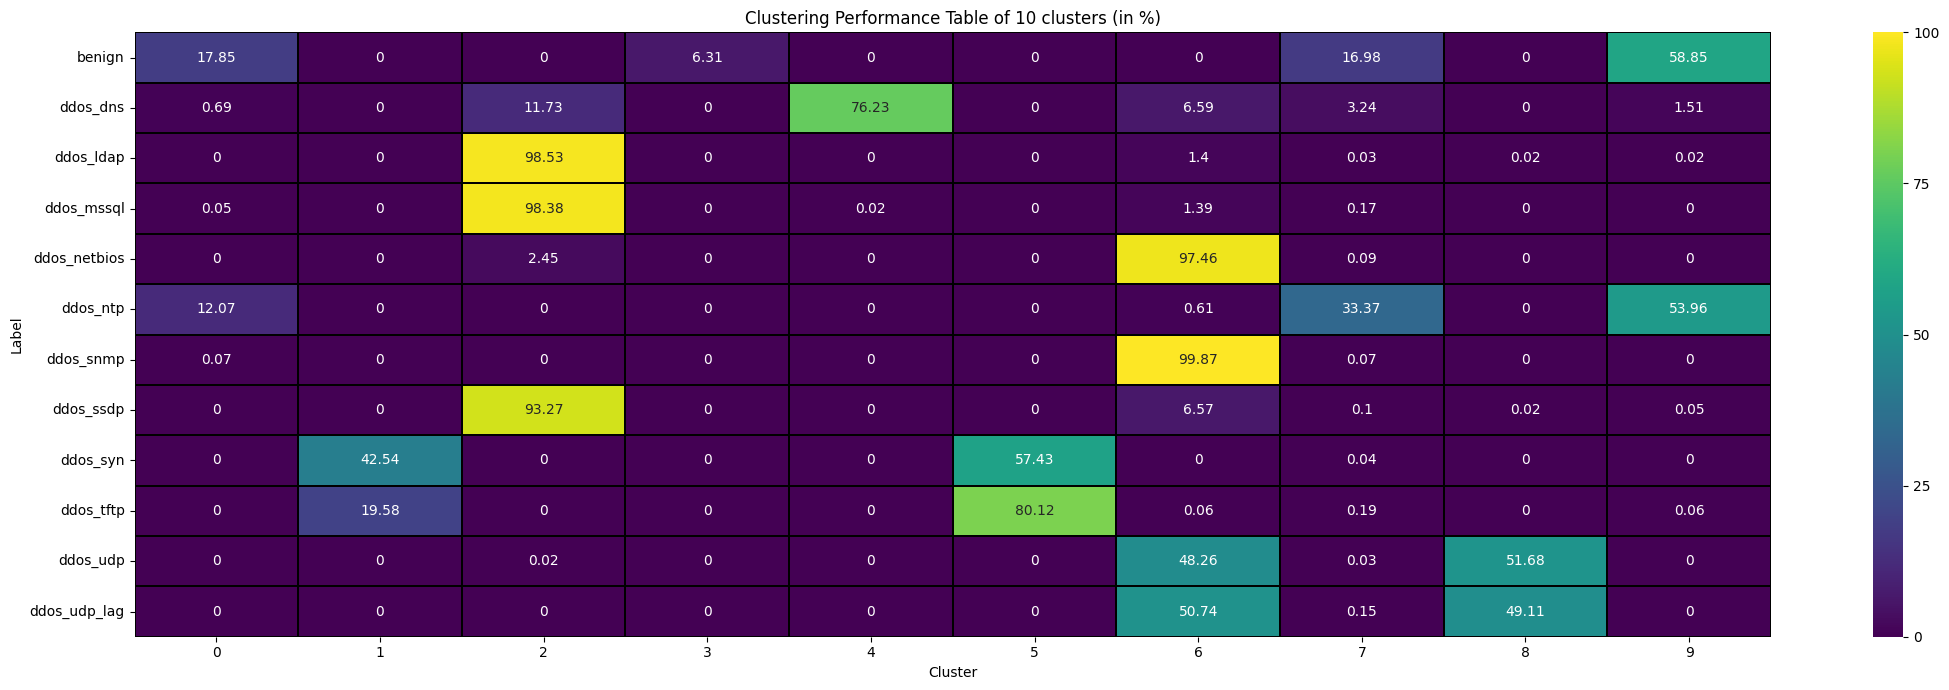

In [27]:
plot_label_cluster_heatmap(results_diag["cluster_labels"][10-2], df_labels, True)

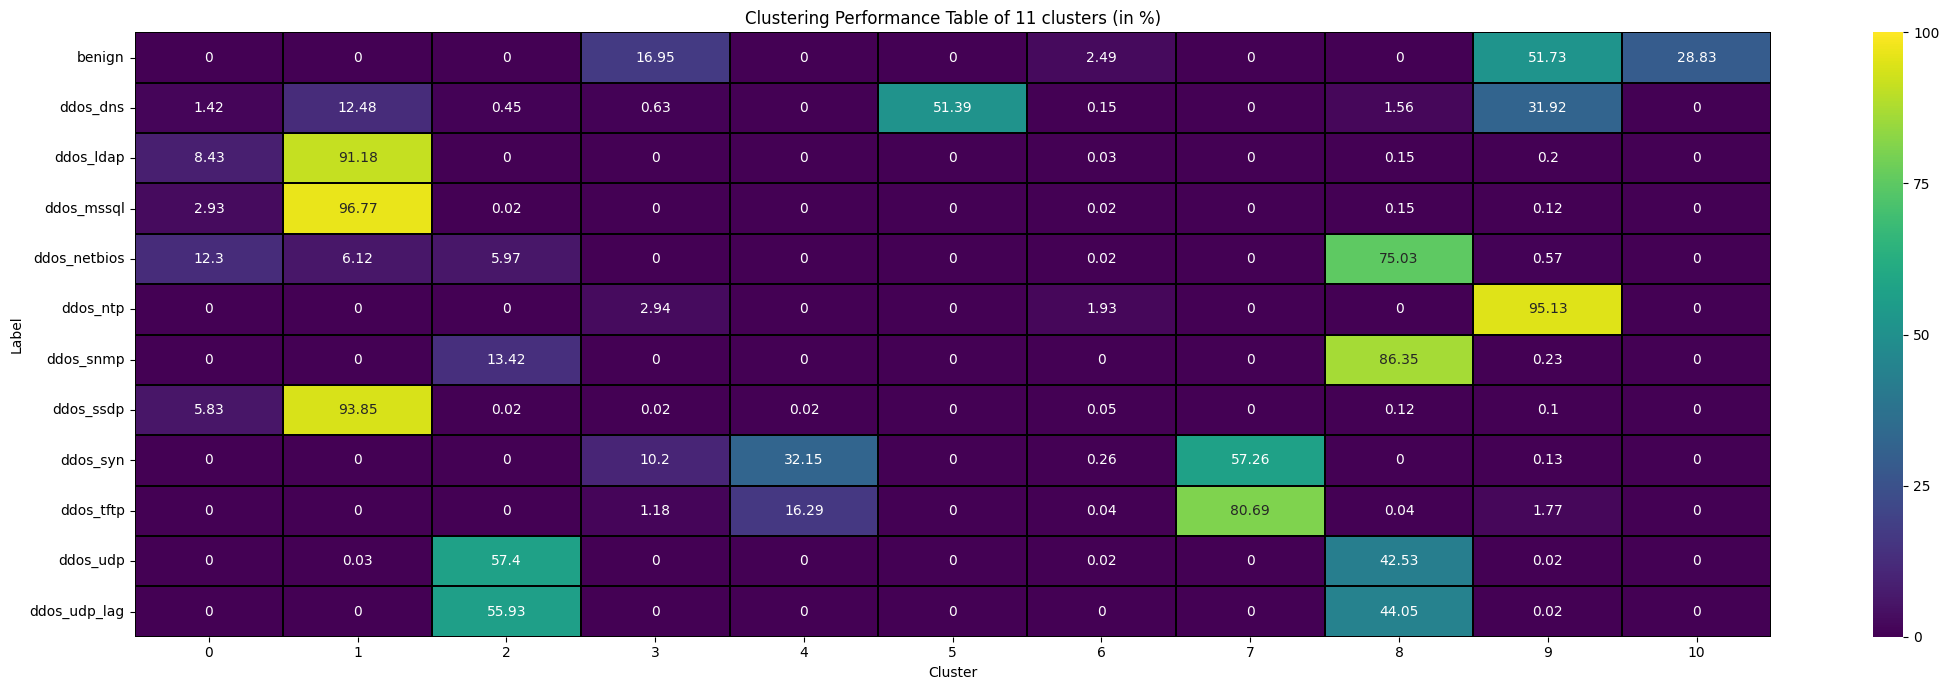

In [28]:
plot_label_cluster_heatmap(results_spherical["cluster_labels"][11-2], df_labels, True)

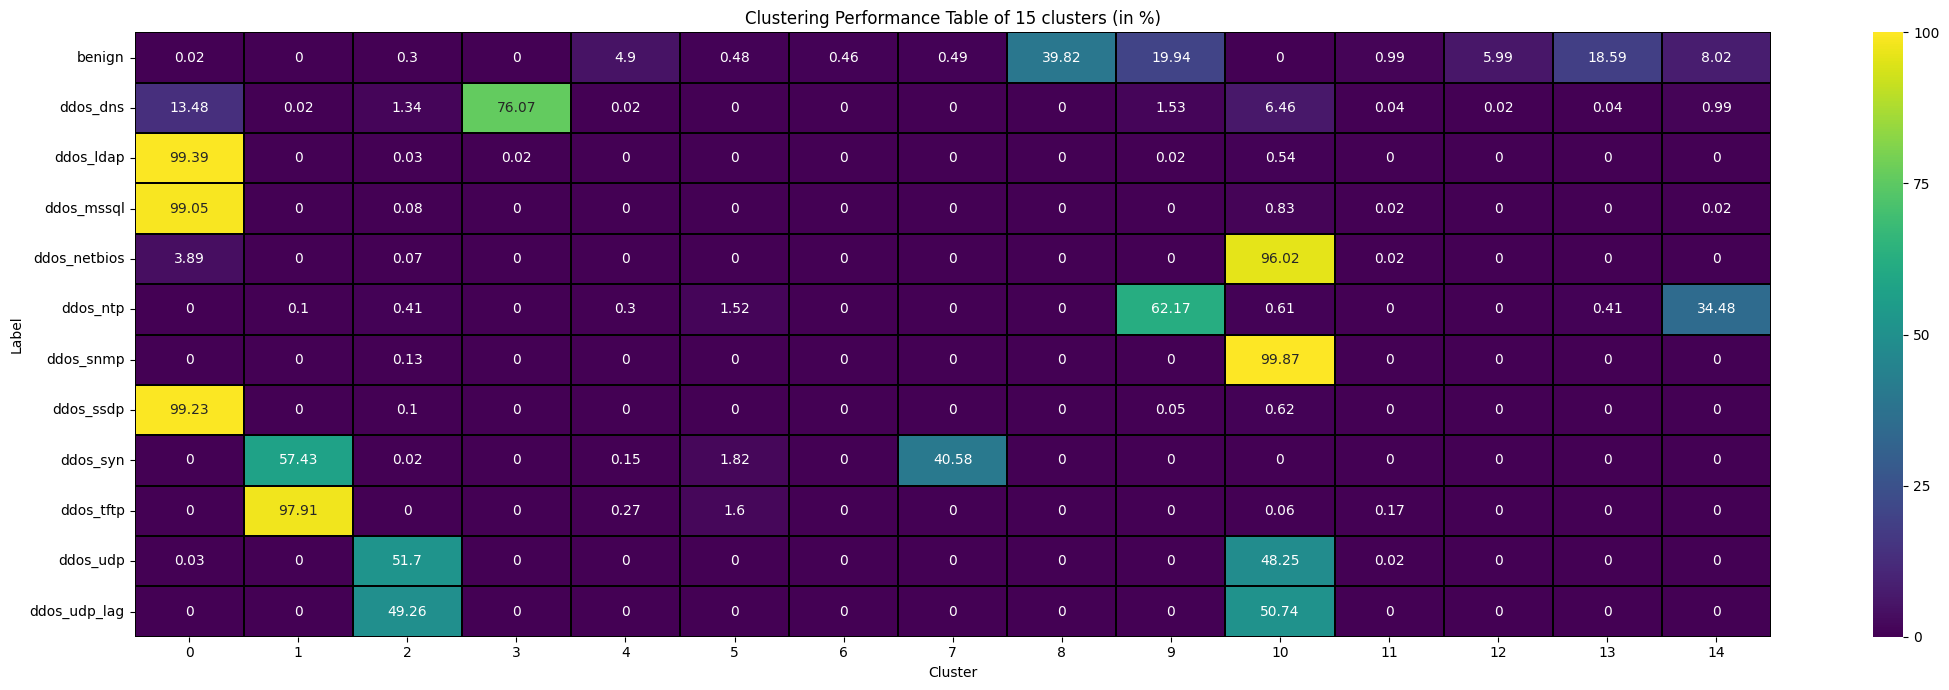

In [29]:
plot_label_cluster_heatmap(results_full["cluster_labels"][15-2], df_labels, True)

# Calculating best_k and its k_means metrics

In [48]:
best_k = 15
best_cv_type = "diag"

In [49]:
results_best_k = gmm_with_info(df=df_s_np, df_labels=df_labels, k=best_k, cv_type=best_cv_type, n_samples=None, print_info=True)

## GMM results (k=15, - Covariance type: diag)
---
GMM total log-likelihood score:, 318.28
Silhouette Score : 0.42
Rand Index (RI): 0.85
Adjusted Rand Index (ARI): 0.38
Effetive size of each cluster: [0.2801566  0.11468111 0.09308987 0.06326375 0.00468565 0.00235052
 0.00452996 0.05208674 0.03309516 0.02789583 0.28724015 0.00481017
 0.00129284 0.01592491 0.01489675]
Number of iterations: 18



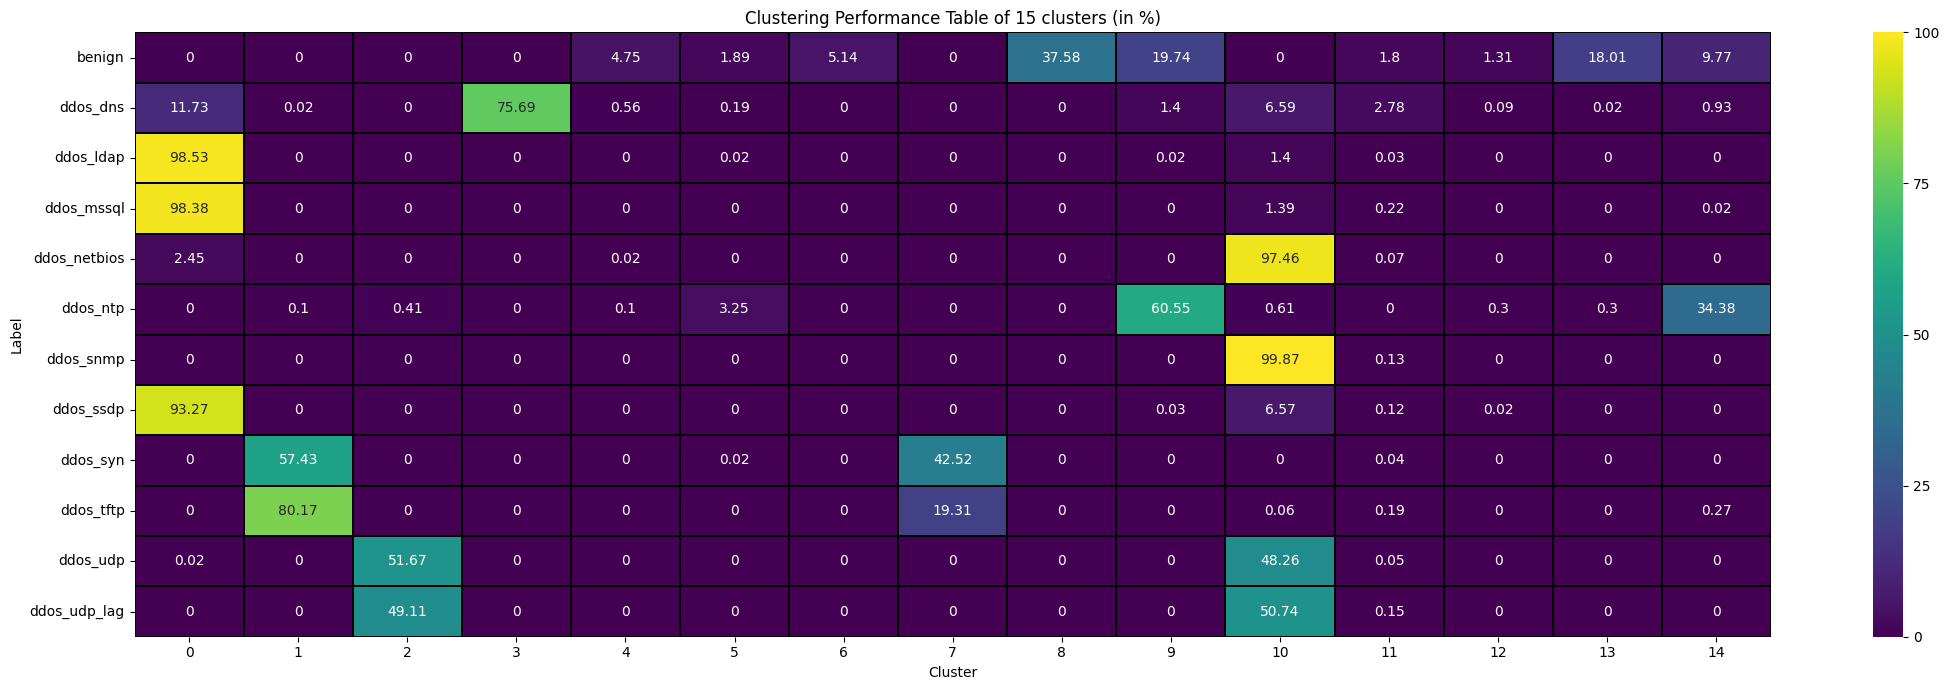

In [70]:
plot_label_cluster_heatmap(results_best_k["cluster_labels"], df_labels, True)

#  Analysis of the detected clusters

### 2D plot with first 2 components of PCA

In [50]:
def plot_clustering_2d(df, cl_labels, n_cluster, cv_type, centroids):
    centroids_pca = pca.transform(centroids)

    plt.figure(figsize=(14, 7))
    sns.scatterplot(x=df_pca[:,0], y=df_pca[:,1], hue=cl_labels, palette='tab10', s=30)
    plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='x', s=70, linewidths=2, color='black', label='Centroids')
    
    plt.title(f"GMM Clustering ({n_cluster} cluster) PCA 2D - Covariance type: {cv_type}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.legend(title="Cluster",bbox_to_anchor=(1.02, 0.5), loc='center left')
    plt.tight_layout()
    plt.show()

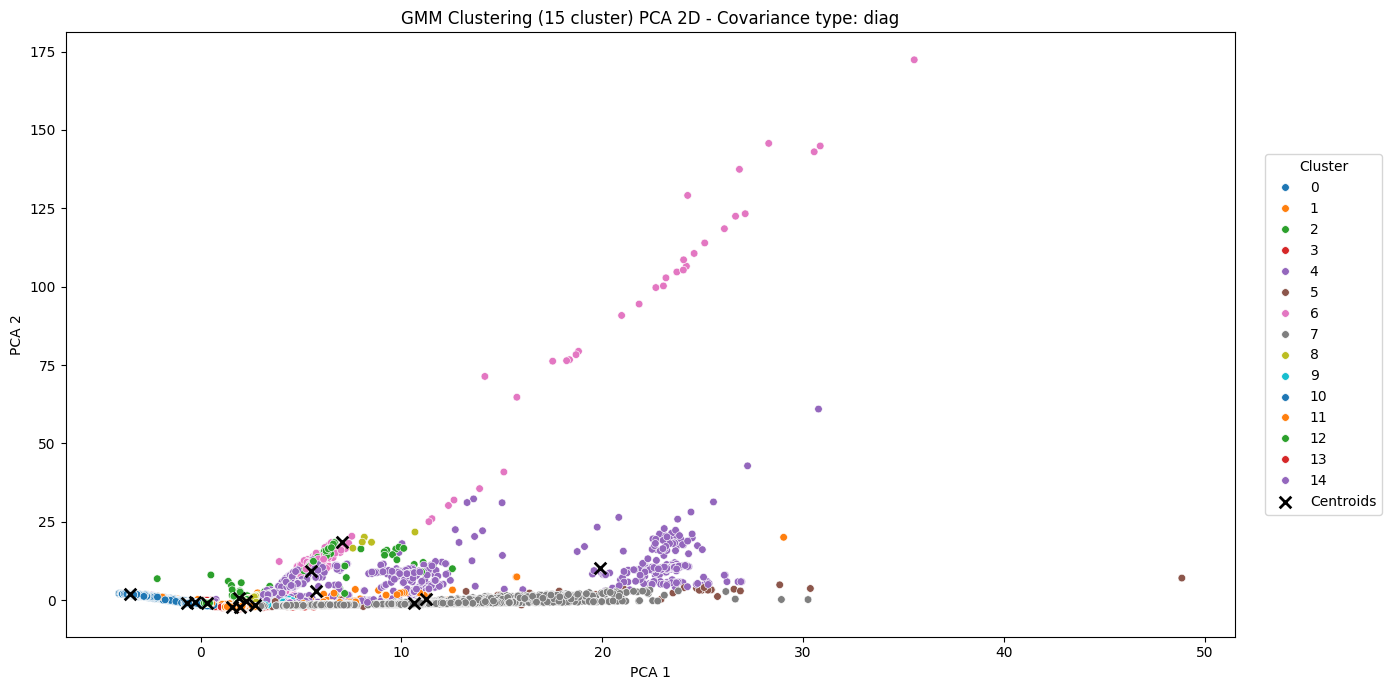

In [51]:
plot_clustering_2d(df_pca,results_best_k["cluster_labels"],results_best_k["k"], best_cv_type, results_best_k["centroids"])

### 3D plot with first 3 components of PCA

In [52]:
def plot_clustering_3d(df_pca, cl_labels, n_cluster, cv_type):
    fig = plt.figure(figsize=(14, 7))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(df_pca[:,0], df_pca[:,1], df_pca[:,2], c=cl_labels, cmap='tab10', s=30)
    ax.set_title(f"GMM Clustering ({n_cluster} cluster) PCA 3D - Covariance type: {cv_type}")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.set_zlabel("PCA 3")


    handles, labels = scatter.legend_elements(num=n_cluster)
    ax.legend(handles=handles, labels=labels, title="Cluster", bbox_to_anchor=(1.06, 0.5), loc='center left')


    plt.tight_layout()
    plt.show()

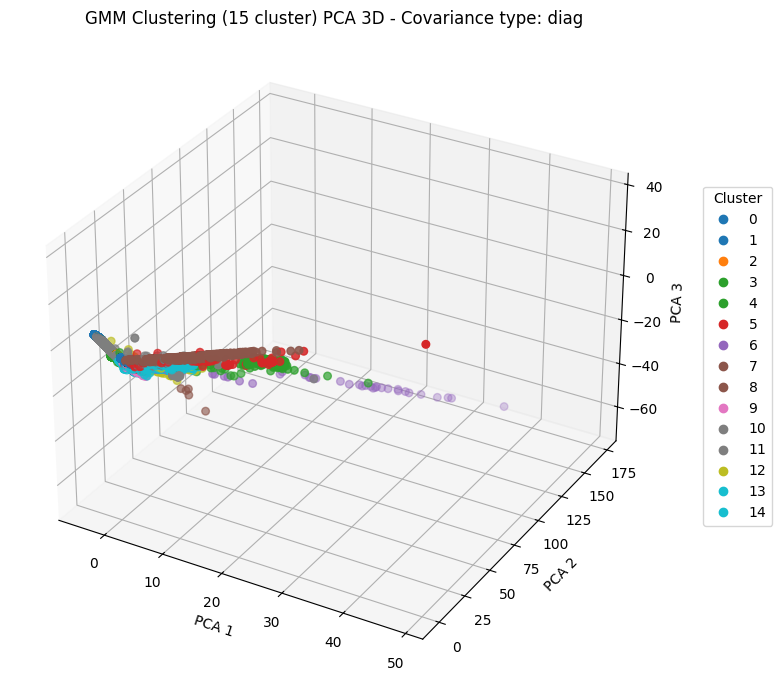

In [53]:
plot_clustering_3d(df_pca,results_best_k["cluster_labels"],results_best_k["k"], best_cv_type)

### UMAP plot

In [54]:
def calculate_umap(checkpoint_file, df, cluster_labels):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            df_umap = pickle.load(f)
        print(f"df_umap already calculated")
    else:
        reducer = umap.UMAP(n_neighbors=15, n_components=2, min_dist=0.1, random_state=42)
        df_umap = reducer.fit_transform(df)
        df_umap = pd.DataFrame(data=df_umap, columns=['UMAP D1', 'UMAP D2'])
        df_umap['Clusters'] = cluster_labels
        with open(checkpoint_file, "wb") as f:
            pickle.dump(df_umap, f)
        print(f"df_umap saved in {checkpoint_file}")
    return df_umap

In [58]:
checkpointFile = f"./saved_results/gmm_df_umap_{best_cv_type}_{best_k}.pkl"
df_umap = calculate_umap(checkpointFile, df_s_np, results_best_k["cluster_labels"])

df_umap already calculated


In [59]:
def plot_umap(df_umap, k_list, cv_type):
    plt.figure(figsize=(14,7))
    sns.scatterplot(
        x='UMAP D1',
        y='UMAP D2',
        hue='Clusters',
        palette=sns.color_palette("tab10", k_list),
        data=df_umap,
        alpha=0.7)
    
    plt.title(f"Cluster visualization with UMAP - Covariance type: {cv_type}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.grid()
    plt.legend(title="Cluster",bbox_to_anchor=(1.02, 0.5), loc='center left')
    plt.tight_layout()
    plt.show()

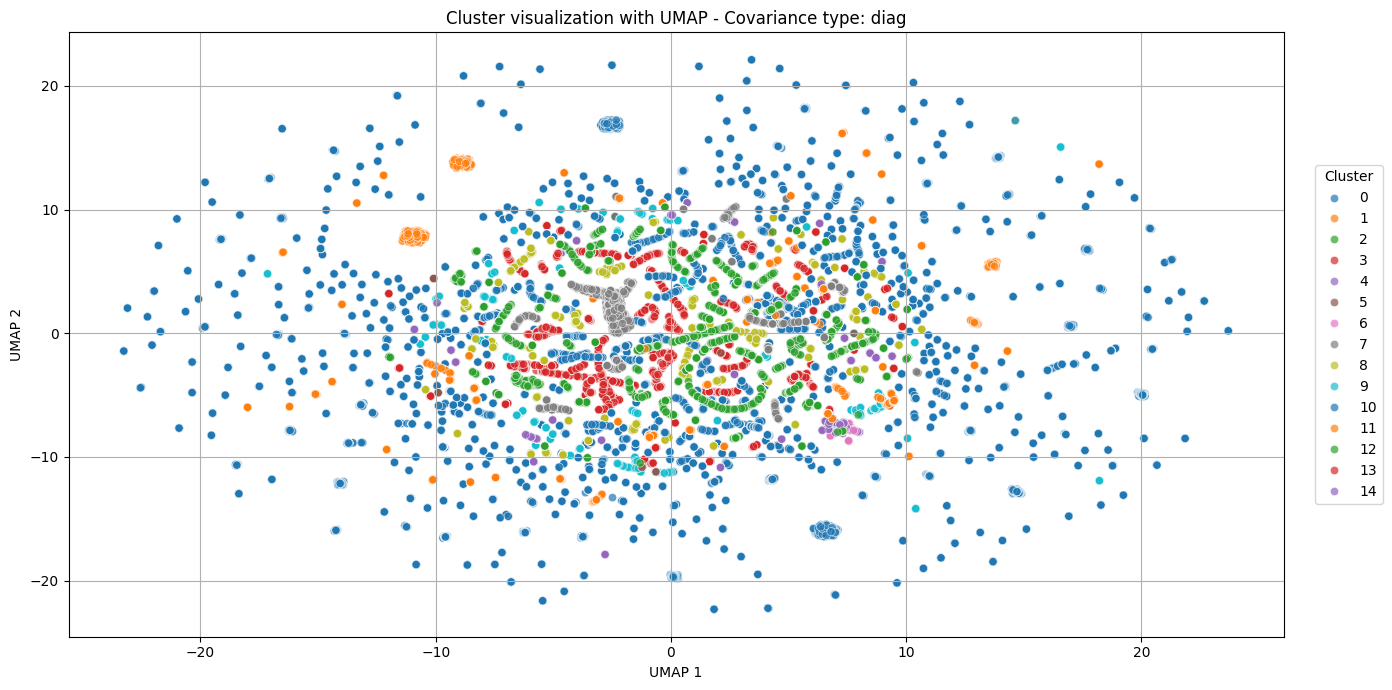

In [60]:
plot_umap(df_umap,results_best_k["k"],best_cv_type)

In [61]:
def plot_ecdf_comparison(cluster_sizes, ground_truth_sizes, cv_type):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    
    sns.ecdfplot(cluster_sizes, ax=ax[0], color='blue', lw=2)
    ax[0].set_xlabel("Number of flows per cluster")
    ax[0].set_ylabel("ECDF")
    ax[0].set_title(f"ECDF dei Cluster (Covariance type: {cv_type})")
    ax[0].grid(True, linestyle='--', alpha=0.6)
    
    sns.ecdfplot(ground_truth_sizes, ax=ax[1], color='blue', lw=2)
    ax[1].set_xlabel("Number of flow per label")
    ax[1].set_ylabel("ECDF")
    ax[1].set_title("ECDF of Ground Truth")
    ax[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.suptitle("Confront ECDF Cluster vs Ground Truth")
    
    plt.tight_layout()
    plt.show()

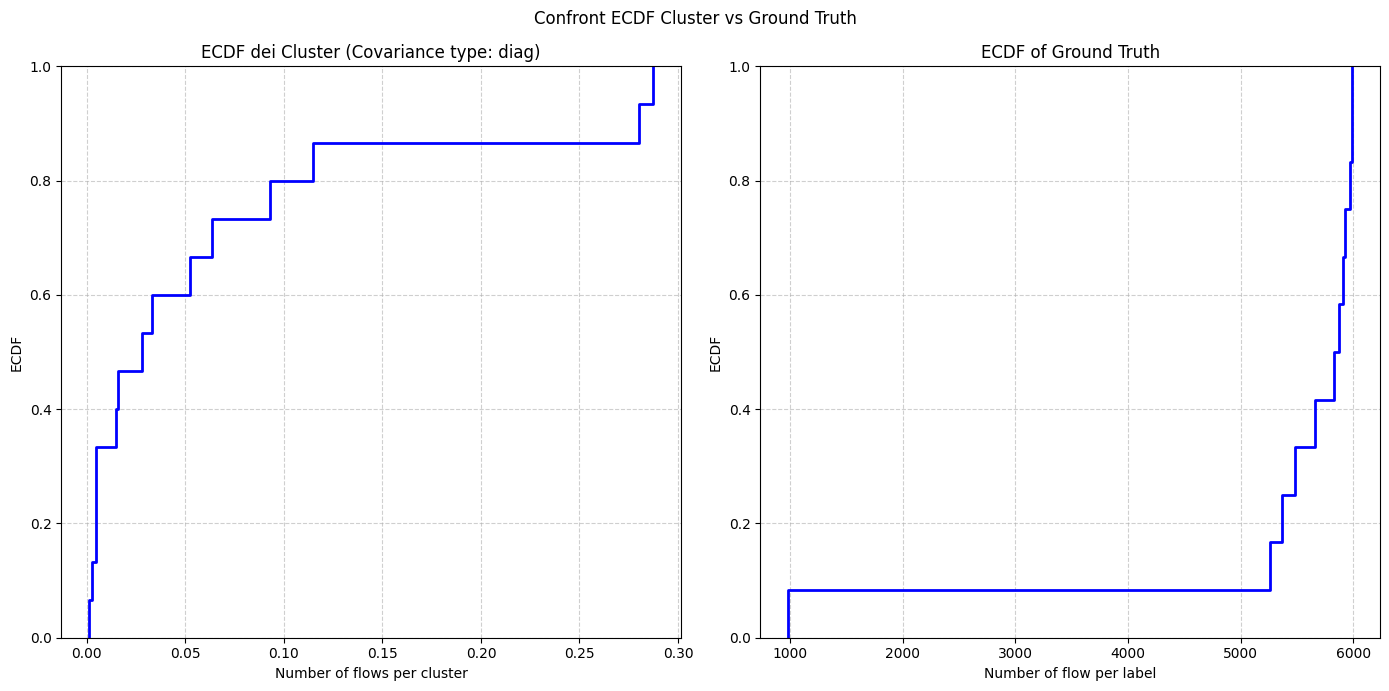

In [62]:
plot_ecdf_comparison(results_best_k['cluster_sizes'],label_counts.values,best_cv_type)

In [63]:
def plot_comparison_bar(cluster_sizes, ground_truth_sizes, cv_type):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    
    ax[0].bar(range(len(cluster_sizes)), sorted(cluster_sizes, reverse=True), color='blue', alpha=0.7)
    ax[0].set_xlabel("Cluster Index (Sorted by size)")
    ax[0].set_ylabel("Number of flows")
    ax[0].set_title(f"Cluster Size Distribution (Covariance type: {cv_type})")
    ax[0].grid(True, axis="y", linestyle='--', alpha=0.6)
    
    ax[1].bar(range(len(ground_truth_sizes)), sorted(ground_truth_sizes, reverse=True), color='blue', alpha=0.7)
    ax[1].set_xlabel("Label Index (Sorted by size)")
    ax[1].set_ylabel("Number of flows")
    ax[1].set_title("Ground Truth Label Distribution")
    ax[1].grid(True, axis="y", linestyle='--', alpha=0.6)
    
    plt.suptitle("Comparison: Cluster Volumes vs Ground Truth Volumes", fontsize=16)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

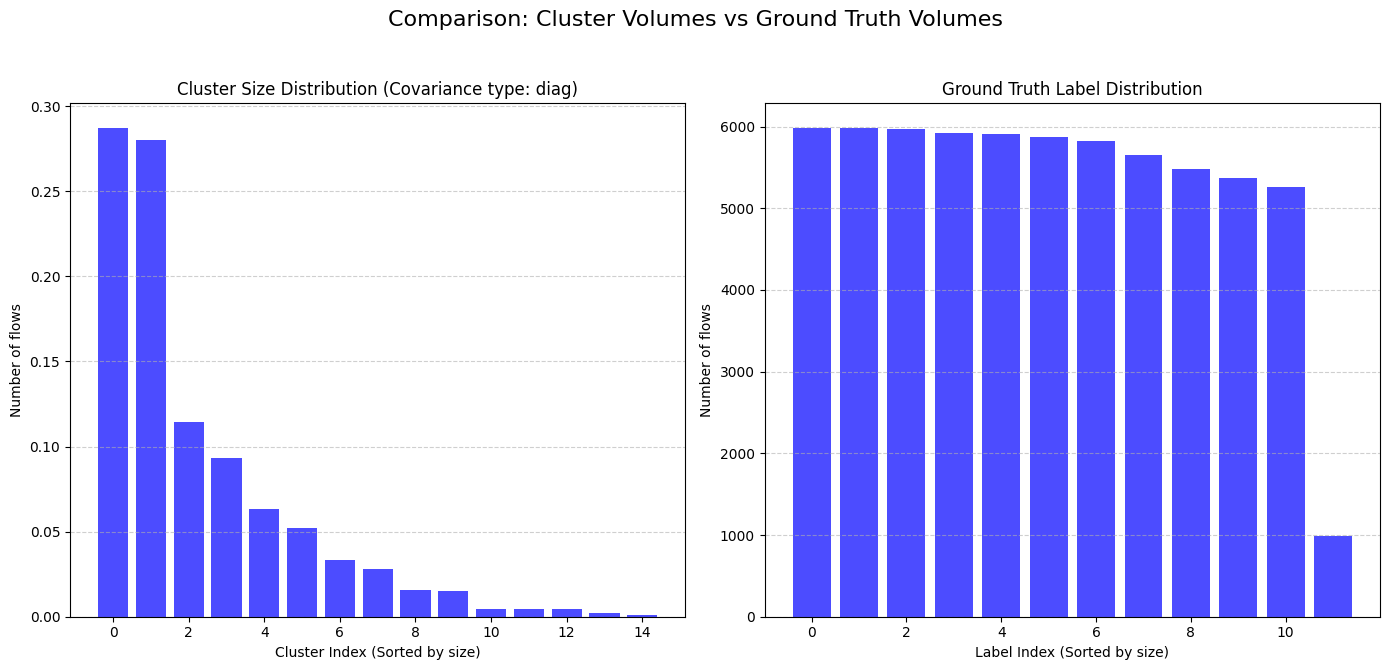

In [64]:
plot_comparison_bar(results_best_k['cluster_sizes'],label_counts.values,best_cv_type)

In [65]:
def silhouette_per_cluster(checkpoint_file, df, labels):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            sil_cluster = pickle.load(f)
        print(f"Already calculated.")
    else:
        sil_samples = silhouette_samples(df, labels)

        sil_cluster_list = []
        for c in np.unique(labels):
            sil_cluster_list.append(sil_samples[labels == c].mean())
        
        sil_cluster = np.array(sil_cluster_list)

        with open(checkpoint_file, "wb") as f:
            pickle.dump(sil_cluster, f)
        print(f"Silhouette per cluster saved in {checkpoint_file}")

    return sil_cluster

In [69]:
checkpointFile = f"./saved_results/gmm_sil_euclidean_clusters_{best_cv_type}_{best_k}.pkl"
sil_clusters = silhouette_per_cluster(checkpointFile, df_s_np,results_best_k['cluster_labels'])

Already calculated.


In [67]:
def plot_silhouette_per_cluster(sil_cluster, cv_type):
    plt.figure(figsize=(14,7))
    plt.bar(range(len(sil_cluster)), sil_cluster)
    plt.axhline(np.mean(sil_cluster), linestyle='--')
    plt.xlabel("Cluster ID")
    plt.ylabel("Mean silhouette")
    plt.title(f"Mean silhouette per cluster - Covariance type: {cv_type}")
    plt.grid(axis="y")
    plt.show()

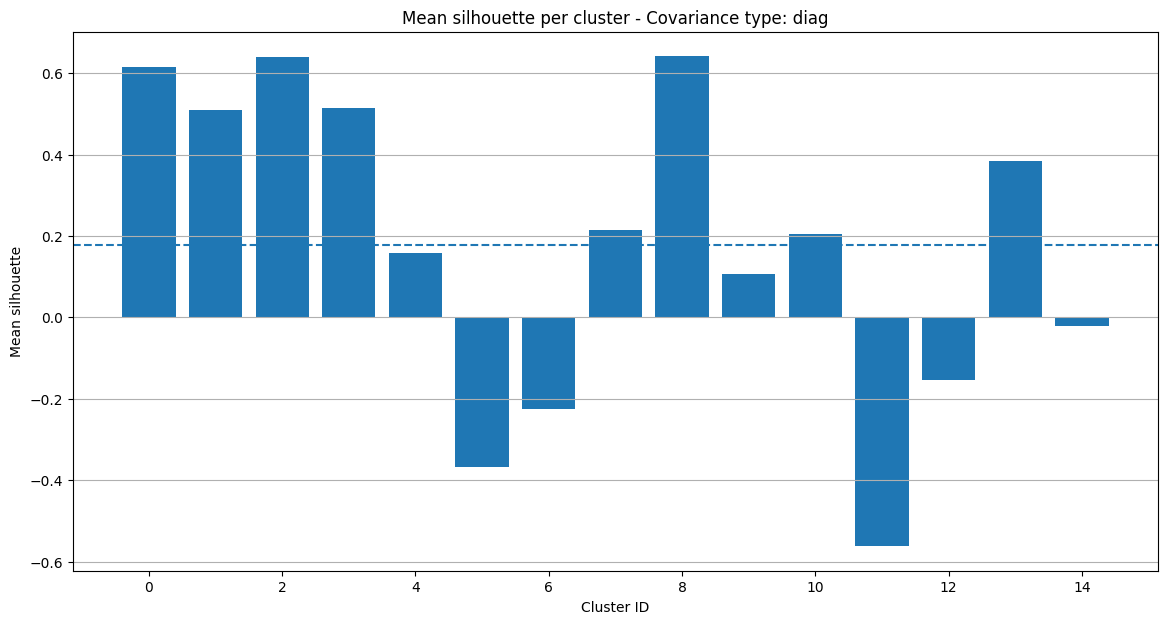

In [68]:
plot_silhouette_per_cluster(sil_clusters,best_cv_type)